# TP1 — Prédire un nombre : la régression avec un réseau de neurones
**ÉNONCÉ** · Durée estimée : **une demi-journée**

## 🎯 Ce que vous allez apprendre
- La différence entre **régression** (prédire un nombre) et classification (prédire une catégorie)
- Pourquoi la dernière couche n'a **pas** d'activation, et pourquoi on utilise la perte **MSE**
- Lire **MAE, RMSE et R²** et savoir ce qu'ils disent
- Reconnaître le **sous-apprentissage** (réseau trop petit) et le surapprentissage (trop peu de données)
- Constater qu'**un réseau n'est pas toujours meilleur** qu'une méthode simple

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`np.random.default_rng`  ·  `plt.scatter`  ·  `train_test_split`  ·  `LinearRegression`  ·  `r2_score`  ·  `mean_absolute_error`  ·  `keras.Sequential`  ·  `layers.Dense`  ·  `model.compile`  ·  `model.fit`  ·  `model.predict`  ·  `StandardScaler`  ·  `load_diabetes`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [3]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Les données : une courbe et du bruit
En **régression**, on prédit un **nombre** (ici la hauteur `y` d'une courbe à partir de sa position `x`). Nous fabriquons les données nous-mêmes : un sinus, plus un peu de bruit aléatoire. Une **droite** ne pourra pas suivre cette courbe, un **réseau** si.

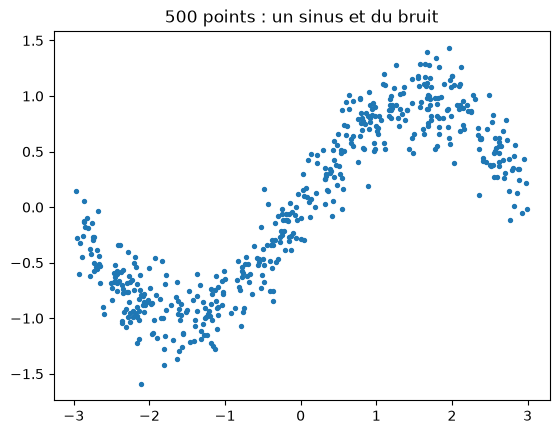

In [2]:
rng = np.random.default_rng(42)
x = rng.uniform(-3, 3, 500)
y = np.sin(x) + rng.normal(0, 0.2, 500)
plt.scatter(x, y, s=8); plt.title("500 points : un sinus et du bruit"); plt.show()

## 🎯 Étape 2 — Découper en apprentissage et test
On garde **20 % des points de côté** : le réseau ne les verra jamais pendant l'apprentissage. Ils serviront de verdict final. Keras attend des entrées **à 2 dimensions** : `x` doit devenir un tableau de forme `(500, 1)`.

**À faire :** Faites `X` (500 lignes, 1 colonne) à partir de `x`, puis découpez en `x_train`, `x_test`, `y_train`, `y_test` : **20 % de test**, `random_state=42`.

> 💡 **Indice** : `reshape(-1, 1)` met un vecteur en colonne. `train_test_split` renvoie 4 morceaux dans un ordre précis : lisez sa documentation.

In [3]:
# TODO : créer x_train, x_test, y_train, y_test

X = x.reshape(-1, 1)
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Taille train : ", x_train.shape)
print("taille test : ", x_test.shape)


Taille train :  (400, 1)
taille test :  (100, 1)


In [4]:
# ✅ Contrôle (ne pas modifier)
controle(x_train.shape == (400, 1) and x_test.shape == (100, 1), 'Découpage correct : 400 / 100', 'Attendu (400, 1) et (100, 1)')

✅ Découpage correct : 400 / 100


## 🎯 Étape 3 — La référence : une droite
Avant tout réseau, on regarde ce que fait **la méthode la plus simple** : une droite. Le **R²** mesure la part de variation expliquée : **1 = parfait, 0 = pas mieux que prédire toujours la moyenne**.

**À faire :** Entraînez une régression linéaire sur `x_train`, puis calculez son **R² sur le test** dans une variable `r2_lineaire`.

> 💡 **Indice** : `LinearRegression`, ses méthodes `fit` et `predict`, puis `r2_score(vrais, prédits)`.

In [5]:
from sklearn.linear_model import LinearRegression
# calculer r2_lineaire
reg_lineaire = LinearRegression()
reg_lineaire.fit(x_train, y_train)
y_pred = reg_lineaire.predict(x_test)
r2_lineaire = r2_score(y_test, y_pred)
print("R² =", r2_lineaire)


R² = 0.6533625638476794


In [6]:
# ✅ Contrôle (ne pas modifier)
controle(0.5 < r2_lineaire < 0.8, 'R² de la droite plausible', 'Attendu un R² entre 0.5 et 0.8 : une droite explique une partie seulement de la courbe')

✅ R² de la droite plausible


## 🎯 Étape 4 — Construire le réseau
Un réseau de régression ressemble à celui d'une classification, avec **deux différences** : la **dernière couche n'a pas d'activation** (elle doit pouvoir sortir n'importe quel nombre, pas seulement entre 0 et 1), et la **perte** est la **MSE** (erreur quadratique moyenne : la moyenne des carrés des écarts).

**À faire :** Construisez `modele` : entrée de taille 1, **deux couches cachées de 32 neurones (ReLU)**, **une sortie de 1 neurone sans activation**. Compilez avec l'optimiseur **adam**, la perte **mse** et la métrique **mae**. Affichez le résumé.

> 💡 **Indice** : `keras.Sequential([...])`, `layers.Input`, `layers.Dense`, `model.compile`, `model.summary`.

In [7]:
keras.utils.set_random_seed(42)
# TODO : construire et compiler modele     #todo
modele = keras.Sequential([
    keras.Input(shape=(1,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)  # pas d'activation : sortie linéaire
])

modele.compile(optimizer="adam", loss="mse", metrics=["mae"])

modele.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,153 (4.50 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# ✅ Contrôle (ne pas modifier)
controle(modele.count_params() == 1153, 'Réseau correct : 1 153 paramètres', 'Attendu 1 153 paramètres, obtenu ' + str(modele.count_params()) + ' : vérifiez les couches')

✅ Réseau correct : 1 153 paramètres


## 🎯 Étape 5 — Entraîner
Un **epoch** est un passage complet sur les données d'apprentissage. On met aussi **20 % de l'apprentissage de côté** (`validation_split`) : à chaque epoch, on mesure l'erreur sur ces points que le réseau n'utilise pas pour se corriger.

**À faire :** Entraînez `modele` : **200 epochs**, **batch de 32**, **20 % de validation**, sans affichage. Stockez le résultat dans `histoire`.

> 💡 **Indice** : `model.fit(...)` renvoie un objet « historique ». Cherchez les arguments `epochs`, `batch_size`, `validation_split`, `verbose`.

In [9]:
# TODO : entraîner modele et stocker le résultat dans histoire

histoire = modele.fit(
    x_train,
    y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

In [10]:
# ✅ Contrôle (ne pas modifier)
controle(len(histoire.history['loss']) == 200, '200 epochs effectués', 'Attendu 200 epochs')

✅ 200 epochs effectués


## Étape 6 — Lire la courbe de perte
La perte (MSE) doit **baisser puis se stabiliser**. La courbe orange (validation) est notre détecteur de triche.

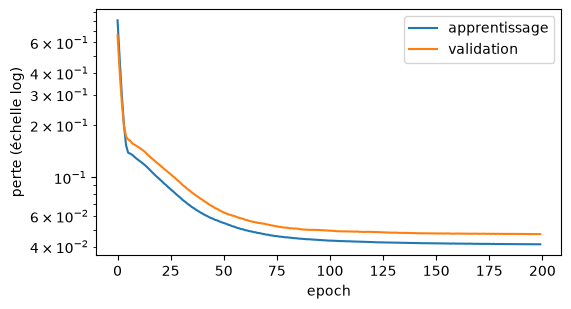

In [11]:
plt.figure(figsize=(6, 3.2))
plt.plot(histoire.history["loss"], label="apprentissage"); plt.plot(histoire.history["val_loss"], label="validation")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("perte (échelle log)"); plt.legend(); plt.show()

### ✍️ Question
**À partir de quel epoch environ la courbe devient-elle plate ? Les 200 epochs étaient-ils nécessaires ?**

Réponse: 

La courbe chute très vite pendant les 5 premiers epochs, puis baisse lentement et devient plate vers l’epoch 100 (au plus tard 125). Les pertes d’apprentissage et de validation se stabilisent alors autour de 0,04 à 0,05, soit près du plancher fixé par le bruit des données (0,2² = 0,04). Les 200 epochs n’étaient donc pas tous nécessaires : la seconde moitié n’améliore presque rien, sans pour autant provoquer de surapprentissage puisque la validation ne remonte pas. Un arrêt précoce (EarlyStopping) aurait arrêté l’entraînement vers 100 à 125 epochs et économisé la moitié du calcul.

> 
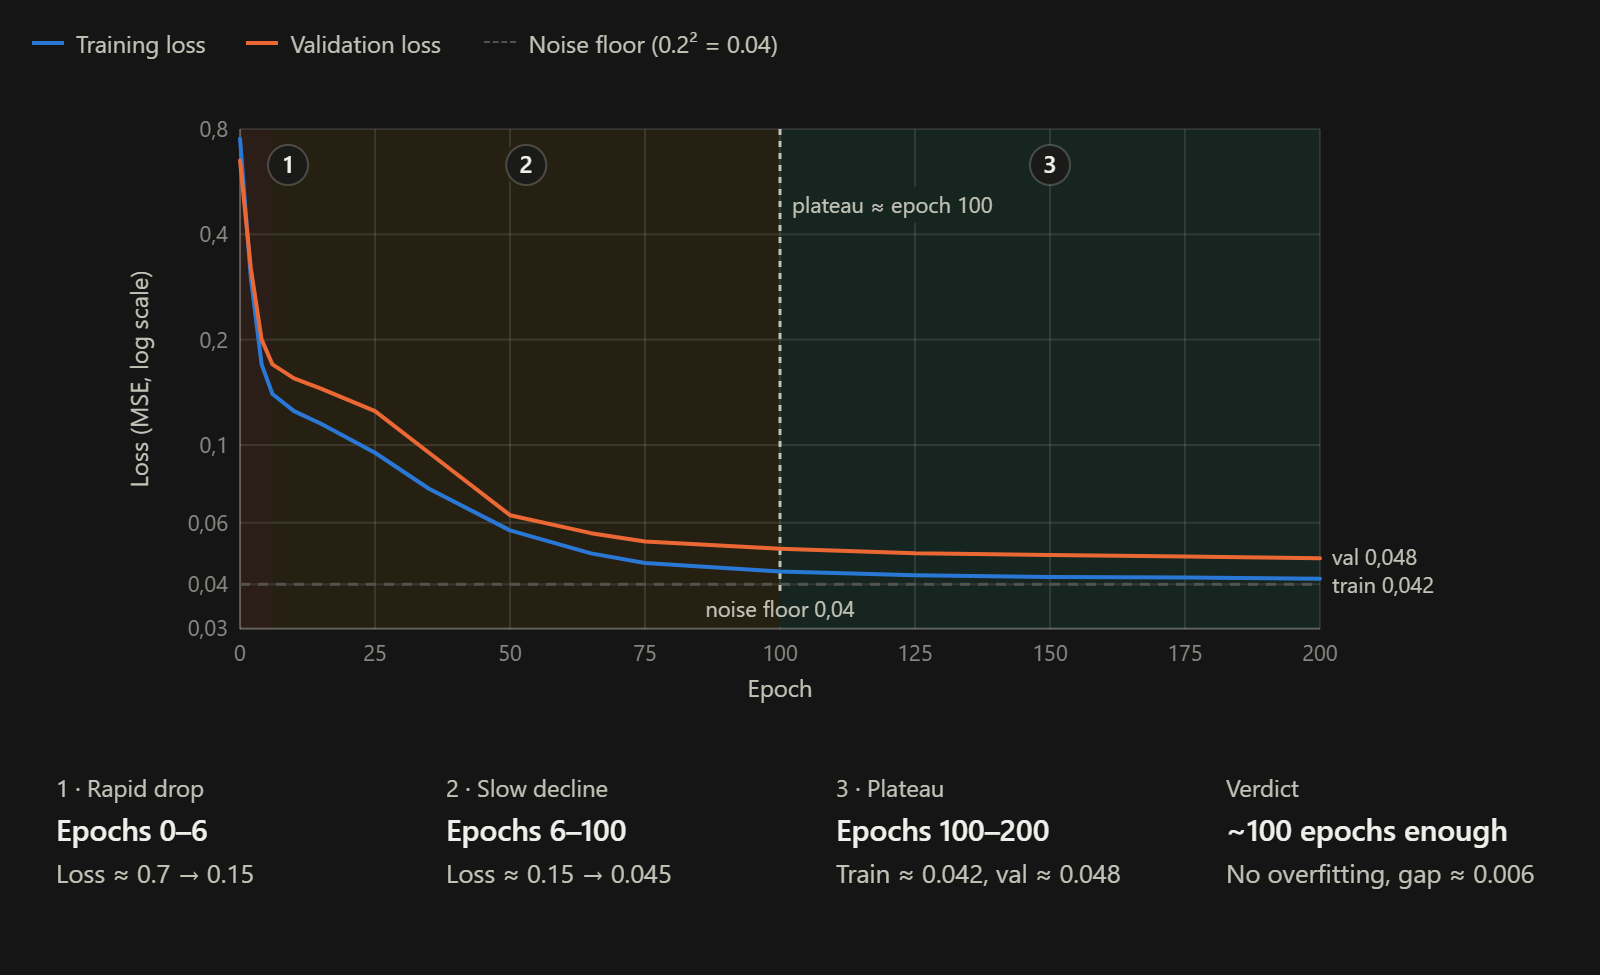

## 🎯 Étape 7 — Évaluer : trois mesures de l'erreur
Sur le test, trois chiffres complémentaires :
- **MAE** : l'erreur moyenne, dans l'unité de `y` (facile à expliquer à un non-spécialiste) ;
- **RMSE** : comme la MAE, mais les **grosses erreurs pèsent plus** ;
- **R²** : de 0 à 1, la part de variation expliquée.

**À faire :** Prédisez `y_pred` sur `x_test` (tableau à une dimension), puis calculez `r2_reseau`, `mae` et `rmse`. Le RMSE est la racine de la moyenne des carrés des écarts.

> 💡 **Indice** : `model.predict(...)` renvoie un tableau à 2 dimensions : `.ravel()` le met à plat. `mean_absolute_error`, `r2_score`, `np.sqrt`, `np.mean`.

In [12]:
# TODO : calculer y_pred, r2_reseau, mae, rmse

from sklearn.metrics import mean_absolute_error, r2_score

y_pred = modele.predict(x_test, verbose=0).ravel()

r2_reseau = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))

print(f"R²   : {r2_reseau:.3f}")
print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")

R²   : 0.933
MAE  : 0.163
RMSE : 0.204


In [13]:
# ✅ Contrôle (ne pas modifier)
controle(r2_reseau > 0.85 and r2_reseau > r2_lineaire, 'Le réseau bat la droite', 'Attendu un R² du réseau supérieur à 0.85 et à celui de la droite')

✅ Le réseau bat la droite


## Étape 8 — Voir ce que le réseau a appris
On trace la courbe prédite par le réseau (rouge) contre la vraie courbe (gris pointillé). C'est la meilleure façon de **comprendre** ce qu'un modèle a fait.

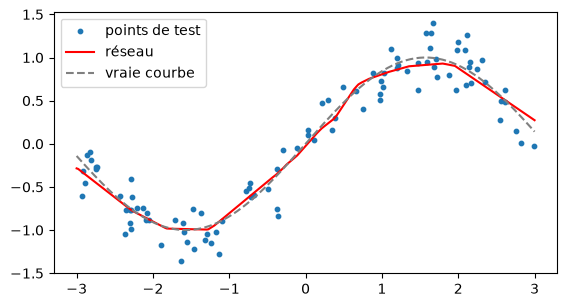

In [14]:
xs = np.linspace(-3, 3, 300).reshape(-1, 1)
plt.figure(figsize=(6.5, 3.4))
plt.scatter(x_test, y_test, s=10, label="points de test")
plt.plot(xs, modele.predict(xs, verbose=0), color="red", label="réseau")
plt.plot(xs, np.sin(xs), "--", color="gray", label="vraie courbe")
plt.legend(); plt.show()

## 🎯 Étape 9 — Expérience : combien de neurones faut-il ?
Un réseau trop petit ne peut pas suivre la courbe : c'est le **sous-apprentissage**. Mesurons-le.

**À faire :** Pour des réseaux à **une seule couche cachée** de **1, 4, 32 puis 256 neurones** (200 epochs, batch 32, sans validation), calculez le **R² sur le test**. Rangez les résultats dans un dictionnaire `resultats` (clé = nombre de neurones). Tracez les 4 courbes prédites côte à côte.

> 💡 **Indice** : Une boucle `for n in (1, 4, 32, 256)`. Pensez à refixer la graine (`set_random_seed`) à chaque tour pour comparer à armes égales.

  1 neurones : R² = 0.590
  4 neurones : R² = 0.857
 32 neurones : R² = 0.926
256 neurones : R² = 0.935


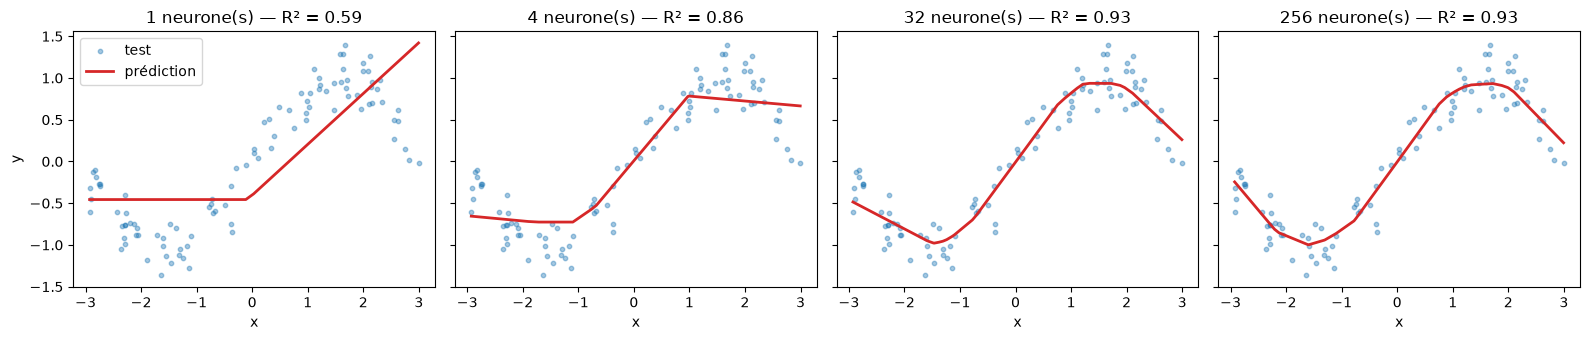

In [19]:
# boucle sur 1, 4, 32, 256 neurones
resultats = {}
predictions = {}

for n in (1, 4, 32, 256):
    keras.utils.set_random_seed(42)  # même graine à chaque tour

    m = keras.Sequential([
        keras.Input(shape=(1,)),
        layers.Dense(n, activation="relu"),
        layers.Dense(1),
    ])
    m.compile(optimizer="adam", loss="mse")
    m.fit(x_train, y_train, epochs=200, batch_size=32, verbose=0)

    y_pred = m.predict(x_test, verbose=0).ravel()
    resultats[n] = r2_score(y_test, y_pred)
    predictions[n] = y_pred
    print(f"{n:>3} neurones : R² = {resultats[n]:.3f}")

# 4 graphiques côte à côte
ordre = np.argsort(np.ravel(x_test))
xs = np.ravel(x_test)[ordre]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, n in zip(axes, resultats):
    ax.scatter(x_test, y_test, s=10, alpha=0.4, label="test")
    ax.plot(xs, predictions[n][ordre], color="tab:red", lw=2, label="prédiction")
    ax.set_title(f"{n} neurone(s) — R² = {resultats[n]:.2f}")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend()
plt.tight_layout()
plt.show()


In [16]:
# ✅ Contrôle (ne pas modifier)
controle(len(resultats) == 4 and resultats[1] < resultats[32], 'Un seul neurone fait moins bien que 32', 'Attendu 4 résultats, avec R² de 1 neurone < R² de 32 neurones')

✅ Un seul neurone fait moins bien que 32


### ✍️ Question
**Que se passe-t-il avec un seul neurone ? Passer de 32 à 256 neurones change-t-il beaucoup le résultat ?**

*Réponse:*

Avec un seul neurone, le réseau calcule  `w₂` · `ReLU(w₁·x + b₁) + b₂`, soit au plus une droite avec un coude. Il capte une partie de la tendance `(R² = 0,59)`, mais il ne peut pas suivre une courbe qui change de direction : près de la moitié de la variation reste inexpliquée. C’est du sous-apprentissage : le modèle est trop petit pour la forme à apprendre, et l’entraîner plus longtemps n’y changerait rien. Le R² progresse ensuite nettement avec la taille `(0,86 pour 4 neurones, 0,93 pour 32)`.

Passer de `32 à 256 neurones` ne change presque rien : le `R²` passe de `0,926 à 0,935`, soit un gain de `0,009`. Dès `32 neurones`, le réseau a assez de coudes pour épouser la courbe, et le `R²` est limité par le bruit des données plutôt que par la taille du modèle. Multiplier le nombre de neurones par 8 ne rapporte donc qu’un gain négligeable.

> 

## 🎯 Étape 10 — Expérience : trop peu de données
Cette fois c'est l'inverse : un **gros** réseau (2 couches de 256 neurones) mais **très peu de données**. Il peut alors mémoriser chaque point, bruit compris : c'est le **surapprentissage**.

**À faire :** N'utilisez que les **15 premiers points** de `x_train` / `y_train`. Entraînez le gros réseau **500 epochs** (batch 8). Calculez `r2_train` (sur ces 15 points) et `r2_test` (sur tout le test). Tracez la courbe prédite.

> 💡 **Indice** : Découpez avec `x_train[:15]`. Comparez les deux R² : que valent-ils chacun ?

R² train : 0.974
R² test  : 0.793


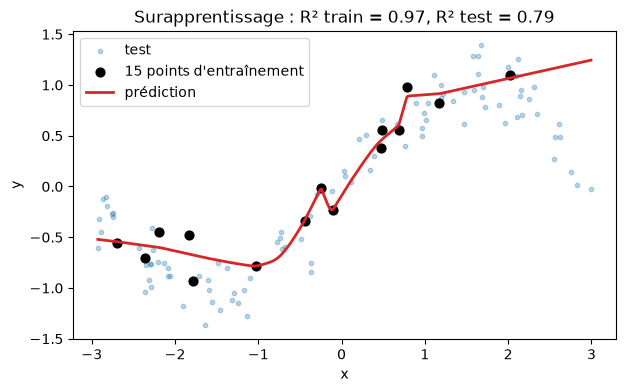

In [20]:
# Calculer r2_train et r2_test avec seulement 15 points
x_petit, y_petit = x_train[:15], y_train[:15]

keras.utils.set_random_seed(42)
gros = keras.Sequential([
    keras.Input(shape=(1,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(1),
])
gros.compile(optimizer="adam", loss="mse")
gros.fit(x_petit, y_petit, epochs=500, batch_size=8, verbose=0)

r2_train = r2_score(y_petit, gros.predict(x_petit, verbose=0).ravel())
r2_test = r2_score(y_test, gros.predict(x_test, verbose=0).ravel())
print(f"R² train : {r2_train:.3f}")
print(f"R² test  : {r2_test:.3f}")

# courbe prédite sur une grille régulière
grille = np.linspace(np.min(x_test), np.max(x_test), 400).reshape(-1, 1)
plt.figure(figsize=(7, 4))
plt.scatter(x_test, y_test, s=10, alpha=0.3, label="test")
plt.scatter(x_petit, y_petit, s=40, color="black", label="15 points d'entraînement")
plt.plot(grille, gros.predict(grille, verbose=0).ravel(), color="tab:red", lw=2, label="prédiction")
plt.xlabel("x"); plt.ylabel("y")
plt.title(f"Surapprentissage : R² train = {r2_train:.2f}, R² test = {r2_test:.2f}")
plt.legend()
plt.show()

In [21]:
# ✅ Contrôle (ne pas modifier)
controle(r2_train > r2_test, 'R² d\'apprentissage supérieur au R² de test : signe de surapprentissage', 'Attendu r2_train > r2_test')

✅ R² d'apprentissage supérieur au R² de test : signe de surapprentissage


### ✍️ Question
**Comparez R² d'apprentissage et R² de test. Que vous dit l'écart ? Que faudrait-il pour le réduire ?**

*Réponse :*

`R² d’apprentissage = 0,974` contre R² de `test = 0,793`. L’écart est d’environ `0,18` : le réseau explique presque toute la variation des 15 points qu’il a vus, mais nettement moins celle de données nouvelles. Il a en partie mémorisé ces 15 points, bruit compris, au lieu de n’apprendre que la forme générale de la courbe. C’est du surapprentissage : un bon score d’entraînement ne prouve rien, seul le test mesure la capacité à généraliser. Le modèle est trop flexible (plus de 66 000 paramètres) pour 15 observations. À titre de comparaison, un réseau de `32 neurones` entraîné sur toutes les données atteint `0,926` sur le test. 

## 🎯 Étape 11 — Sur des données réelles : la progression du diabète
Reprenez **toute la démarche** sur un vrai jeu : `load_diabetes` (442 patients, 10 mesures médicales, cible = indice de progression de la maladie). Ici les 10 colonnes ont des échelles différentes : il faut les **mettre à l'échelle**, en calculant la moyenne et l'écart-type **sur l'apprentissage seul**.

**À faire :** 1) Découpez (20 % de test, `random_state=42`) vers `Xd_train`, `Xd_test`, `yd_train`, `yd_test`. 2) Standardisez (fit sur train, transform sur train et test). 3) Régression linéaire → `r2_lin_d`. 4) Réseau **16 puis 8 neurones**, 150 epochs max, batch 16, validation 20 %, **arrêt précoce** (patience 15, `restore_best_weights=True`) → `r2_res_d`.

> 💡 **Indice** : `StandardScaler` : `fit` puis `transform`. `keras.callbacks.EarlyStopping`. Pour un réseau de régression, rappelez-vous la sortie et la perte.

In [4]:
# Tout le pipeline sur le jeu du diabète

import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

# 1) Découpage
X, y = load_diabetes(return_X_y=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2) Standardisation : moyenne et écart-type calculés sur l'apprentissage seul
scaler = StandardScaler()
Xd_train = scaler.fit_transform(Xd_train)
Xd_test = scaler.transform(Xd_test)

# 3) Régression linéaire
lin = LinearRegression().fit(Xd_train, yd_train)
r2_lin_d = r2_score(yd_test, lin.predict(Xd_test))

# 4) Réseau 16 -> 8 avec arrêt précoce
keras.utils.set_random_seed(42)
reseau = keras.Sequential([
    keras.Input(shape=(10,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1),
])
reseau.compile(optimizer="adam", loss="mse")

arret = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
histoire_d = reseau.fit(
    Xd_train, yd_train,
    epochs=150, batch_size=16, validation_split=0.2,
    callbacks=[arret], verbose=0,
)

r2_res_d = r2_score(yd_test, reseau.predict(Xd_test, verbose=0).ravel())

print(f"R² régression linéaire : {r2_lin_d:.3f}")
print(f"R² réseau (16-8)       : {r2_res_d:.3f}")
print(f"Epochs effectués       : {len(histoire_d.history['loss'])}")


R² régression linéaire : 0.453
R² réseau (16-8)       : 0.463
Epochs effectués       : 150


In [25]:
# ✅ Contrôle (ne pas modifier)
controle(0.3 < r2_lin_d < 0.6 and 0.3 < r2_res_d < 0.6, 'Résultats plausibles sur le diabète', 'Attendu des R² entre 0.3 et 0.6 pour les deux méthodes')

✅ Résultats plausibles sur le diabète


### ✍️ Question
**Le réseau bat-il nettement la régression linéaire ? Pourquoi l'avantage est-il faible sur ce jeu ?**

*Réponse
Non : le `R² du réseau (0,463)` dépasse à peine celui de la régression linéaire `(0,453)`, un `écart de 0,010` qui est négligeable. Sur ce jeu, la relation entre les 10 mesures et la cible est surtout linéaire, donc la régression linéaire en capte déjà l'essentiel. Avec `seulement 442 patients (353 pour l'apprentissage)`, le réseau n'a pas assez de données pour exploiter sa flexibilité supplémentaire. Enfin, les mesures n'expliquent qu'une partie de la maladie, ce bruit plafonne le `R²` de tous les modèles, simples ou complexes.

## ✅ Ce qu'il faut retenir
- **Régression** = prédire un nombre : sortie **sans activation**, perte **MSE**, mesures **MAE / RMSE / R²**.
- Le **R²** se lit par rapport à une référence : 0 = pas mieux que la moyenne, 1 = parfait. Comparez **toujours** à une méthode simple.
- **Trop petit** = sous-apprentissage ; **trop gros pour trop peu de données** = surapprentissage.
- Un réseau **n'est pas toujours meilleur** : sur peu de données ou une relation simple, une droite suffit.